# 04 · Predicting a single race

A strict "as-of" replay of the most recent Grand Prix in the data: the model is trained only on
races that happened **before** it, then asked for each driver's podium probability using the
grid, qualifying and form as they stood on race morning.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from f1predict import model as m
from f1predict import plots
from f1predict.config import DATA_PROCESSED
from f1predict.features import FEATURES

plots.apply_style()
df = pd.read_parquet(DATA_PROCESSED / "features.parquet")
target_race = df.sort_values("date")["race_id"].iloc[-1]
race = df[df["race_id"] == target_race]
history = df[df["date"] < race["date"].iloc[0]]
print(f"Predicting {race['season'].iloc[0]} {race['race_name'].iloc[0]} "
      f"using {history['race_id'].nunique()} earlier races")

Predicting 2026 Brazilian Grand Prix using 271 earlier races


In [2]:
models = m.fit_all(history)
scored = m.score(models, race)
scored["podium_prob"] = scored["p_lgbm"]
scored["predicted_rank"] = scored["s_rank"].rank(ascending=False).astype(int)
cols = ["driver_name", "constructor_name", "grid", "podium_prob", "predicted_rank",
        "finish_position", "status"]
scored.sort_values("podium_prob", ascending=False)[cols].head(10).style.format(
    {"podium_prob": "{:.0%}", "grid": "{:.0f}", "finish_position": "{:.0f}"})

,driver_name,constructor_name,grid,podium_prob,predicted_rank,finish_position,status
5527,Andrea Kimi Antonelli,Mercedes,2,67%,1,5,Finished
5523,Lando Norris,McLaren,1,52%,2,1,Finished
5526,George Russell,Mercedes,7,30%,3,4,Finished
5530,Charles Leclerc,Ferrari,14,22%,6,8,Finished
5529,Liam Lawson,RB F1 Team,3,17%,4,7,Finished
5524,Max Verstappen,Red Bull,21,14%,7,2,Finished
5525,Isack Hadjar,Red Bull,5,10%,5,3,Finished
5531,Lewis Hamilton,Ferrari,20,6%,9,9,Lapped
5532,Nico Hülkenberg,Audi,4,2%,8,10,Lapped
5528,Oscar Piastri,McLaren,10,1%,10,6,Finished


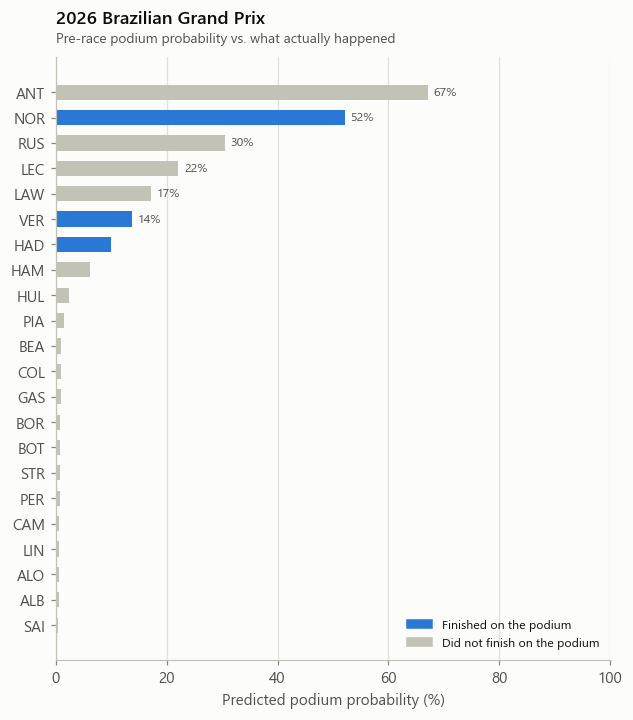

In [3]:
fig = plots.race_probabilities(scored, "p_lgbm")
plots.save(fig, "latest_race_prediction")
plt.show()

In [4]:
print(m.race_ranking_metrics(scored, "p_lgbm"))
print("Expected podium places (sum of probabilities):", round(scored["p_lgbm"].sum(), 2))

{'top3_hit': 0.3333333333333333, 'winner_hit': 0.0, 'spearman': 0.7843026538678713}
Expected podium places (sum of probabilities): 2.31


## Using the saved model on new inputs

`models/podium_lgbm.joblib` holds the classifier trained on all races. To score an upcoming
race, build the same feature rows (e.g. by appending the qualifying result to the history and
re-running `build_features`) and call `predict_proba`.

In [5]:
bundle = m.load_bundle()
probs = bundle["model"].predict_proba(race[bundle["features"]])[:, 1]
print(f"Saved model trained through {bundle['trained_through']}; in-sample probabilities for "
      f"this race sum to {probs.sum():.2f}")
assert bundle["features"] == FEATURES

Saved model trained through 2026-11-08; in-sample probabilities for this race sum to 2.38
